# EDA & data-quality audit — Track 2: Steel Plant Energy Forecasting
Goal: forecast `next_interval_Usage_kWh` (electricity in the next 15 minutes). Every number below is computed by the cell above it.

In [1]:
import pandas as pd, numpy as np, matplotlib
matplotlib.use('Agg'); import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
from features import TARGET, DATE_FMT, true_timestamp
df = pd.read_csv('train.csv')
print(df.shape); print(df.dtypes.to_string()); df.head()

(28031, 12)
date                                        str
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                                  str
Day_of_week                                 str
Load_Type                                   str
next_interval_Usage_kWh                 float64


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,3.28


## 1. Basic quality checks

In [2]:
print('missing values per column:', df.isna().sum().sum())
print('duplicate rows:', df.duplicated().sum())
print('duplicate raw date strings:', df['date'].duplicated().sum())
df.describe().T.round(3)

missing values per column: 0
duplicate rows: 0
duplicate raw date strings: 0


,count,mean,std,min,25%,50%,75%,max
Usage_kWh,28031.0,27.924,33.920,2.45,3.13,4.61,51.26,153.14
Lagging_Current_Reactive.Power_kVarh,28031.0,13.255,16.484,0.00,2.74,5.04,22.90,96.91
Leading_Current_Reactive_Power_kVarh,28031.0,3.860,7.481,0.00,0.00,0.00,2.09,27.76
CO2(tCO2),28031.0,0.012,0.016,0.00,0.00,0.00,0.02,0.07
Lagging_Current_Power_Factor,28031.0,79.947,19.389,36.94,61.64,87.98,99.07,100.00
Leading_Current_Power_Factor,28031.0,84.540,30.379,12.50,99.82,100.00,100.00,100.00
NSM,28031.0,42751.525,24939.761,0.00,21600.00,43200.00,64350.00,85500.00
next_interval_Usage_kWh,28031.0,27.927,33.922,2.45,3.13,4.61,51.26,153.14


In [3]:
for c in ['WeekStatus','Day_of_week','Load_Type']:
    print(c, df[c].value_counts().to_dict())
print('Leading power factor == 100 in', round((df['Leading_Current_Power_Factor']==100).mean()*100,1), '% of rows (leading reactive power is 0 there)')
print('Leading reactive power == 0 in', round((df['Leading_Current_Reactive_Power_kVarh']==0).mean()*100,1), '% of rows')

WeekStatus {'Weekday': 20159, 'Weekend': 7872}
Day_of_week {'Monday': 4032, 'Tuesday': 4032, 'Wednesday': 4032, 'Thursday': 4032, 'Friday': 4031, 'Saturday': 3936, 'Sunday': 3936}
Load_Type {'Light_Load': 14367, 'Medium_Load': 7808, 'Maximum_Load': 5856}
Leading power factor == 100 in 71.8 % of rows (leading reactive power is 0 there)
Leading reactive power == 0 in 69.5 % of rows


## 2. Dates: a data-quality problem found and fixed
The `date` column is **not** monotonic as given. The midnight reading (`NSM = 0`) is stamped `00:00` of the day it *closes* (it is really 24:00), so it appears to jump backwards 23 h 45 m.

In [4]:
raw = pd.to_datetime(df['date'], format=DATE_FMT)
print('raw monotonic?', raw.is_monotonic_increasing, '| backward jumps:', int((raw.diff()<pd.Timedelta(0)).sum()))
print(df.iloc[93:98][['date','NSM','Day_of_week','Usage_kWh','next_interval_Usage_kWh']])
ts = true_timestamp(df['date'], df['NSM'])
print('fixed monotonic?', ts.is_monotonic_increasing)
print(ts.diff().dropna().value_counts())
print('range:', ts.min(), '->', ts.max(), '| 292 days x 96 = 28032 slots, rows =', len(df))

raw monotonic? False | backward jumps: 291
                date    NSM Day_of_week  Usage_kWh  next_interval_Usage_kWh
93  01/01/2018 23:30  84600      Monday       3.24                     3.67
94  01/01/2018 23:45  85500      Monday       3.67                     3.42
95  01/01/2018 00:00      0      Monday       3.42                     3.20
96  02/01/2018 00:15    900     Tuesday       3.20                     3.85
97  02/01/2018 00:30   1800     Tuesday       3.85                     3.28
fixed monotonic? True
0 days 00:15:00    28030
Name: count, dtype: int64
range: 2018-01-01 00:15:00 -> 2018-10-19 23:45:00 | 292 days x 96 = 28032 slots, rows = 28031


## 3. Is the target already aligned? (don't shift it again)

In [5]:
aligned = (df[TARGET].iloc[:-1].values == df['Usage_kWh'].iloc[1:].values)
print('next_interval_Usage_kWh == next row Usage_kWh for', aligned.mean()*100, '% of consecutive rows')
print('only the last row has no following row to compare with (its label is the first reading after the file ends).')

next_interval_Usage_kWh == next row Usage_kWh for 100.0 % of consecutive rows
only the last row has no following row to compare with (its label is the first reading after the file ends).


**Consequence:** the label is simply the *next row's* `Usage_kWh`. In a hidden test file, the next row's `Usage_kWh` is therefore the answer — using it would be leakage, so the inference code only looks at rows at or before time *t* (tested in `test_pipeline.py`).

## 4. Target distribution and outliers

skew 1.18 | IQR upper fence 123.5 | rows above fence 271 (1.0%)


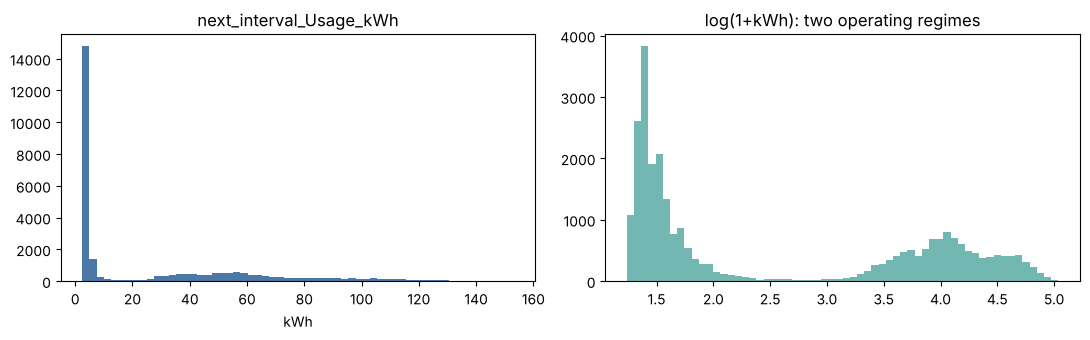

In [6]:
y = df[TARGET]
q1,q3 = y.quantile([.25,.75]); fence = q3+1.5*(q3-q1)
print('skew', round(y.skew(),2), '| IQR upper fence', round(fence,1), '| rows above fence', int((y>fence).sum()), '(%.1f%%)'%((y>fence).mean()*100))
fig,ax = plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(y,bins=60,color='#4C78A8'); ax[0].set_title('next_interval_Usage_kWh'); ax[0].set_xlabel('kWh')
ax[1].hist(np.log1p(y),bins=60,color='#72B7B2'); ax[1].set_title('log(1+kWh): two operating regimes'); plt.tight_layout(); plt.savefig('figures/target_distribution.png',dpi=120); plt.show()

The distribution is bimodal (idle/light load around 3-5 kWh vs. production at 50-80+ kWh). High values are real production peaks, not errors, so we do **not** clip them.

## 5. Consumption patterns

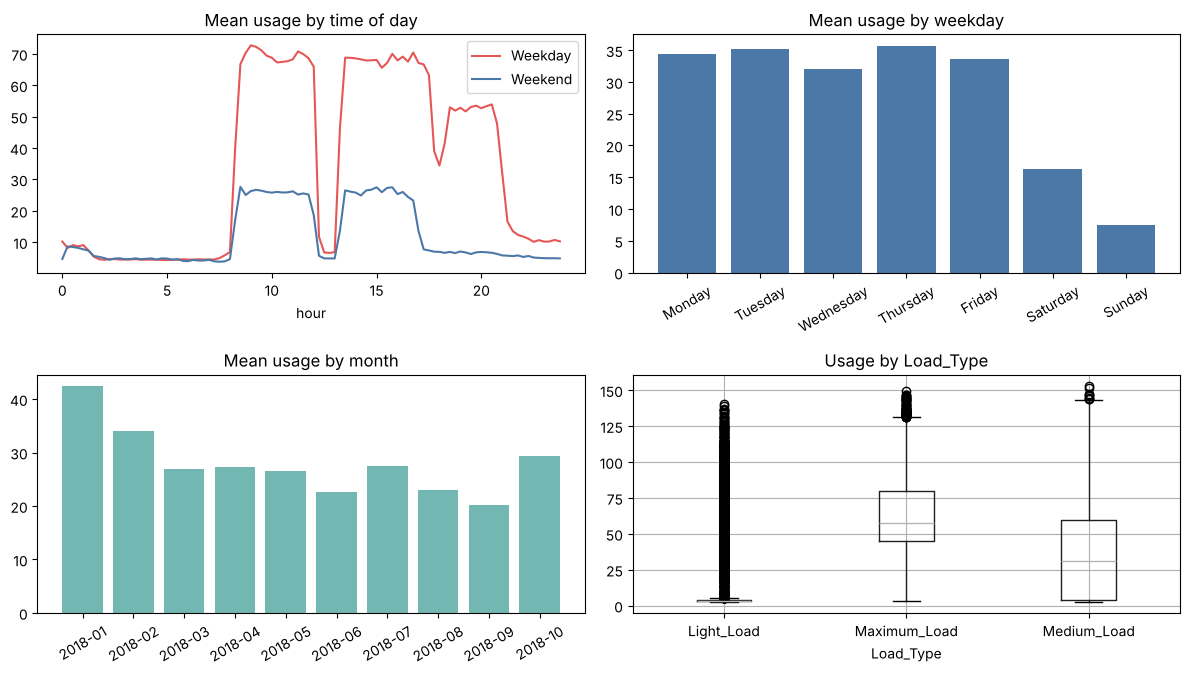

{'Monday': 34.3, 'Tuesday': 35.2, 'Wednesday': 32.1, 'Thursday': 35.7, 'Friday': 33.7, 'Saturday': 16.4, 'Sunday': 7.4}
{'2018-01': 42.4, '2018-02': 34.1, '2018-03': 27.0, '2018-04': 27.4, '2018-05': 26.6, '2018-06': 22.7, '2018-07': 27.4, '2018-08': 23.0, '2018-09': 20.1, '2018-10': 29.3}
{'Weekday': 34.2, 'Weekend': 11.9}


In [7]:
d = df.assign(ts=ts, hour=ts.dt.hour + ts.dt.minute/60, month=ts.dt.to_period('M').astype(str))
fig,ax = plt.subplots(2,2,figsize=(12,7))
for ws,c in [('Weekday','#E45756'),('Weekend','#4C78A8')]:
    g = d[d.WeekStatus==ws].groupby(d.NSM//900*0.25)['Usage_kWh'].mean(); ax[0,0].plot(g.index,g.values,label=ws,color=c)
ax[0,0].set_title('Mean usage by time of day'); ax[0,0].set_xlabel('hour'); ax[0,0].legend()
order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = d.groupby('Day_of_week')['Usage_kWh'].mean().reindex(order); ax[0,1].bar(order,dow.values,color='#4C78A8'); ax[0,1].set_title('Mean usage by weekday'); ax[0,1].tick_params(axis='x',rotation=30)
m = d.groupby('month')['Usage_kWh'].mean(); ax[1,0].bar(m.index,m.values,color='#72B7B2'); ax[1,0].set_title('Mean usage by month'); ax[1,0].tick_params(axis='x',rotation=30)
d.boxplot(column='Usage_kWh',by='Load_Type',ax=ax[1,1]); ax[1,1].set_title('Usage by Load_Type'); plt.suptitle(''); plt.tight_layout(); plt.savefig('figures/consumption_patterns.png',dpi=120); plt.show()
print(dow.round(1).to_dict()); print(m.round(1).to_dict()); print(d.groupby('WeekStatus')['Usage_kWh'].mean().round(1).to_dict())

## 6. Correlations and autocorrelation

In [8]:
num = df.select_dtypes('number').drop(columns=[]); print(num.corr()[TARGET].sort_values(ascending=False).round(3).to_string())
u = df['Usage_kWh']; print({k: round(u.autocorr(k),3) for k in [1,2,4,8,16,96,672]})
print('corr(Usage_t, CO2):', round(df['Usage_kWh'].corr(df['CO2(tCO2)']),3))

next_interval_Usage_kWh                 1.000
Usage_kWh                               0.911
CO2(tCO2)                               0.901
Lagging_Current_Reactive.Power_kVarh    0.806
Lagging_Current_Power_Factor            0.398
Leading_Current_Power_Factor            0.334
NSM                                     0.220
Leading_Current_Reactive_Power_kVarh   -0.297
{1: np.float64(0.911), 2: np.float64(0.834), 4: np.float64(0.689), 8: np.float64(0.545), 16: np.float64(0.328), 96: np.float64(0.604), 672: np.float64(0.668)}
corr(Usage_t, CO2): 0.987


Usage is highly autocorrelated at 15 min (0.91) and only moderately at 1 day / 1 week (0.60 / 0.67). `CO2(tCO2)` is ~ a deterministic function of current usage (a derived quantity), so it adds little beyond `Usage_kWh`.

## 7. Leakage / availability review
| Column | Known at time *t*? | Decision |
|---|---|---|
| `Usage_kWh`, reactive power, power factors, CO2 | yes — measured during interval *t* | use |
| `NSM`, `date`, `WeekStatus`, `Day_of_week`, `Load_Type` | yes — schedule / plant status label supplied in test schema | use |
| `next_interval_Usage_kWh` | **no — it is the label** | never a feature |
| Next row's values / rolling windows that look forward | **no** | never used |
| Lags (`t-1`…), rolling stats ending at *t* | yes | use (built by timestamp, past only) |

`Load_Type` is a plant status label (not a pure function of `Usage_kWh`: e.g. Light_Load rows reach 140 kWh), so it is a legitimate current-interval input — confirmed present in the official column list.

## 8. Regime shift to keep in mind
Monthly mean usage falls from 42 kWh (Jan) to 20 kWh (Sep), and the last 20 % of rows (our validation period, 22 Aug – 19 Oct) has a lower mean target (23.2) than the training period (29.1). Validation therefore tests the model on a genuinely different, quieter period; it also means RMSE/MAE are not directly comparable across months with different load.